# EL ESPEJO DEL MUNDO
### El cine como reflejo de la sociedad

El cine es mucho más que una forma de entretenimiento: es un reflejo de la época en la que nace. A través de sus historias, personajes y temáticas, las películas permiten descubrir los valores, los conflictos, los miedos y las transformaciones que definen a una sociedad.

**EL ESPEJO DEL MUNDO** es un proyecto de análisis exploratorio de datos (EDA) que busca investigar cómo ha evolucionado la representación de diferentes realidades sociales en el cine a lo largo de buena parte del siglo XX, desde 1919 hasta 1989.

Para ello, el estudio se divide en tres grandes etapas históricas y geográficas:

- **1919-1939 | El mundo de entreguerras:** Estados Unidos, Reino Unido y Alemania. Un periodo marcado por los cambios sociales, la industrialización, las tensiones políticas y la incertidumbre previa a la Segunda Guerra Mundial.
- **1940-1960 | Guerra y posguerra:** Estados Unidos, Francia, Japón e Italia. Una época condicionada por los conflictos bélicos, sus consecuencias humanas, la reconstrucción y el nacimiento de nuevos temores sociales.
- **1961-1989 | La transformación de España:** un recorrido desde el franquismo hasta la consolidación de la democracia, analizando los cambios en las libertades, los roles de género, la familia, la sexualidad y el consumo de drogas.

A través de la recopilación, transformación y visualización de datos cinematográficos y sociales, el proyecto pretende identificar patrones, comparar países y periodos históricos y explorar posibles relaciones entre lo que ocurría en la realidad y lo que llegaba a las pantallas.

El objetivo no es demostrar que el cine reproduce fielmente la sociedad, sino descubrir **qué nos cuentan las películas sobre el mundo en el que fueron creadas**.

Porque cada película es también una pequeña fotografía de su tiempo.

*«El cine no solo cuenta historias: también conserva la memoria de las sociedades que las imaginaron».*

In [1]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

Lo primero que necesitamos es construir un gran dataset de películas, a partir del cual sacaremos y filtraremos todas las peliculas que necesitaremos más tarde en cada etapa que estudiaremos.

Para ello, utilizaremos dos sources diferentes, la base de datos de IMDB y la de CMU, ya que ambas poseen datos y atributos que necesitamos, por lo que complementaremos los datos de IMDB con los de CMU.

De IMDB obtendremos datos de name.basic.tsv (para el nombre de los directores), title.basics.tsv (para el id tconst, el título de la película en ingés y el original, el género y el año de estreno) y title.crew.tsv (que contiene los diferentes ids de la bbdd para poder unir las tablas)

In [2]:
# CARGAMOS EL name.basics.tsv de IMDB
imdb_name_basics=pd.read_csv("name.basics.tsv/name.basics.tsv",sep="\t",na_values="\\N")
imdb_name_basics

,nconst,primaryName,birthYear,deathYear,primaryProfession,knownForTitles
0,nm0000001,Fred Astaire,1899.0,1987.0,"actor,miscellaneous,producer","tt0072308,tt0031983,tt0050419,tt0025164"
1,nm0000002,Lauren Bacall,1924.0,2014.0,"actress,miscellaneous,soundtrack","tt0037382,tt0117057,tt0075213,tt0038355"
2,nm0000003,Brigitte Bardot,1934.0,2025.0,"actress,music_department,producer","tt0057345,tt0049189,tt0056404,tt0054452"
3,nm0000004,John Belushi,1949.0,1982.0,"actor,writer,music_department","tt0072562,tt0077975,tt0080455,tt0078723"
4,nm0000005,Ingmar Bergman,1918.0,2007.0,"writer,director,actor","tt0050986,tt0069467,tt0083922,tt0050976"
...,...,...,...,...,...,...
15782041,nm9993714,Romeo del Rosario,NaN,NaN,"animation_department,art_department","tt11657662,tt14069590,tt2455546"
15782042,nm9993716,Essias Loberg,NaN,NaN,NaN,NaN
15782043,nm9993717,Harikrishnan Rajan,NaN,NaN,cinematographer,tt8736744
15782044,nm9993718,Aayush Nair,NaN,NaN,cinematographer,tt8736744


In [ ]:
# Cargamos EL title.basics.tsv de IMDB
imdb_title_basics=pd.read_csv("title.basics.tsv/title.basics.tsv",sep="\t",na_values="\\N")
imdb_title_basics

C:\Users\jaime\AppData\Local\Temp\ipykernel_32788\3509960371.py:2: DtypeWarning: Columns (7: runtimeMinutes) have mixed types. Specify dtype option on import or set low_memory=False.
  imdb_title_basics=pd.read_csv("title.basics.tsv/title.basics.tsv",sep="\t",na_values="\\N")


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894.0,NaN,1.0,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892.0,NaN,5.0,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892.0,NaN,5.0,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892.0,NaN,12.0,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893.0,NaN,1.0,Short
...,...,...,...,...,...,...,...,...,...
12918852,tt9916848,tvEpisode,Episode #3.17,Episode #3.17,0,2009.0,NaN,NaN,Drama
12918853,tt9916850,tvEpisode,Episode #3.19,Episode #3.19,0,2010.0,NaN,NaN,Drama
12918854,tt9916852,tvEpisode,Episode #3.20,Episode #3.20,0,2010.0,NaN,NaN,Drama
12918855,tt9916856,short,The Wind,The Wind,0,2015.0,NaN,27,Short


In [ ]:
# Comprobamos los diferentes tipos de películas que almacena title.basics.tsv
imdb_title_basics.titleType.unique()

<StringArray>
[       'short',        'movie',      'tvShort',      'tvMovie',
    'tvEpisode',     'tvSeries', 'tvMiniSeries',    'tvSpecial',
        'video',    'videoGame',      'tvPilot']
Length: 11, dtype: str

In [ ]:
# Para el estudio, únicamente quiero las películas, por lo que filtraremos por el tipo 'movie'
imdb_title_basics=imdb_title_basics[imdb_title_basics["titleType"]=="movie"]
imdb_title_basics

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
8,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance
144,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport"
498,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN
570,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography"
587,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama
...,...,...,...,...,...,...,...,...,...
12918751,tt9916622,movie,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,0,2015.0,NaN,57,Documentary
12918775,tt9916680,movie,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,0,2007.0,NaN,100,Documentary
12918787,tt9916706,movie,Dankyavar Danka,Dankyavar Danka,0,2013.0,NaN,NaN,Comedy
12918797,tt9916730,movie,6 Gunn,6 Gunn,0,2017.0,NaN,116,Drama


In [ ]:
# De nuevo, comprobamos si está bien filtrada la tabla
imdb_title_basics.titleType.unique()

<StringArray>
['movie']
Length: 1, dtype: str

In [ ]:
# Cargamos el title.crew.tsv de IMDB
imdb_title_crew=pd.read_csv("title.crew.tsv/title.crew.tsv",sep="\t",na_values="\\N")
imdb_title_crew

,tconst,directors,writers
0,tt0000001,nm0005690,NaN
1,tt0000002,nm0721526,NaN
2,tt0000003,nm0721526,nm0721526
3,tt0000004,nm0721526,NaN
4,tt0000005,nm0005690,NaN
...,...,...,...
12917624,tt9916848,nm1485677,"nm9187127,nm1485677,nm9826385,nm9299459,nm1628284"
12917625,tt9916850,nm1485677,"nm9187127,nm1485677,nm9826385,nm1628284"
12917626,tt9916852,nm1485677,"nm9187127,nm1485677,nm9826385,nm9299459,nm1628284"
12917627,tt9916856,nm10538645,nm6951431


In [ ]:
# Unimos imdb_title_basics con imdb_title_crew mediante la PK tconst con un left join, quedándome con el directors de imdb_title_crew
# Almaceno el resultado en my_movies, el que será mi dataset de películas final
my_movies=imdb_title_basics.merge(imdb_title_crew[["tconst","directors"]],on="tconst",how="left")
my_movies

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres,directors
0,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance,nm0085156
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport",nm0714557
2,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN,nm0063413
3,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography",nm0846879
4,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama,nm0141150
...,...,...,...,...,...,...,...,...,...,...
759690,tt9916622,movie,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,0,2015.0,NaN,57,Documentary,"nm9272490,nm9272491"
759691,tt9916680,movie,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,0,2007.0,NaN,100,Documentary,nm0652213
759692,tt9916706,movie,Dankyavar Danka,Dankyavar Danka,0,2013.0,NaN,NaN,Comedy,nm7764440
759693,tt9916730,movie,6 Gunn,6 Gunn,0,2017.0,NaN,116,Drama,nm10538612


In [ ]:
# Con explode dividimos la columna directors (internamente), ya que a veces hay dos códigos por fila
my_movies=my_movies.explode("directors")

In [ ]:
# Ahora unimos my_movies con imdb_name_basics para obtener los nombres de los directores
my_movies=my_movies.merge(imdb_name_basics[["nconst", "primaryName"]],left_on="directors",right_on="nconst",how="left")
my_movies

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres,directors,nconst,primaryName
0,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance,nm0085156,nm0085156,Alexander Black
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport",nm0714557,nm0714557,Enoch J. Rector
2,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN,nm0063413,nm0063413,Ricardo de Baños
3,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography",nm0846879,nm0846879,Charles Tait
4,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama,nm0141150,nm0141150,Michel Carré
...,...,...,...,...,...,...,...,...,...,...,...,...
759690,tt9916622,movie,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,0,2015.0,NaN,57,Documentary,"nm9272490,nm9272491",NaN,NaN
759691,tt9916680,movie,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,0,2007.0,NaN,100,Documentary,nm0652213,nm0652213,Luis Ospina
759692,tt9916706,movie,Dankyavar Danka,Dankyavar Danka,0,2013.0,NaN,NaN,Comedy,nm7764440,nm7764440,Kanchan Nayak
759693,tt9916730,movie,6 Gunn,6 Gunn,0,2017.0,NaN,116,Drama,nm10538612,nm10538612,Kiran Gawade


In [ ]:
# Nos quedamos sólo con estas 5 columnas
my_movies=my_movies[["tconst","primaryTitle","originalTitle","startYear","primaryName"]]

# Cambiamos el nombre de las columnas por uno más intuitivo
my_movies=my_movies.rename(columns={"tconst": "movie_id","primaryTitle": "title","originalTitle": "original_title",\
                                    "startYear": "release_year","primaryName": "director"})
my_movies

,movie_id,title,original_title,release_year,director
0,tt0000009,Miss Jerry,Miss Jerry,1894.0,Alexander Black
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897.0,Enoch J. Rector
2,tt0000502,Bohemios,Bohemios,1905.0,Ricardo de Baños
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906.0,Charles Tait
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907.0,Michel Carré
...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015.0,NaN
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007.0,Luis Ospina
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013.0,Kanchan Nayak
759693,tt9916730,6 Gunn,6 Gunn,2017.0,Kiran Gawade


In [ ]:
# Convertimos el type de release_year de float a int
my_movies["release_year"]=my_movies["release_year"].astype("Int64")
my_movies

,movie_id,title,original_title,release_year,director
0,tt0000009,Miss Jerry,Miss Jerry,1894,Alexander Black
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897,Enoch J. Rector
2,tt0000502,Bohemios,Bohemios,1905,Ricardo de Baños
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,Charles Tait
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907,Michel Carré
...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015,NaN
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007,Luis Ospina
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013,Kanchan Nayak
759693,tt9916730,6 Gunn,6 Gunn,2017,Kiran Gawade


In [ ]:
# Añadimos el género de la película desde imdb_title_basics
my_movies=my_movies.merge(imdb_title_basics[["tconst","genres"]],left_on="movie_id",right_on="tconst",how="left")
my_movies=my_movies.drop(columns=["tconst"])
my_movies=my_movies.rename(columns={"genres":"genres"})
my_movies

,movie_id,title,original_title,release_year,director,genres
0,tt0000009,Miss Jerry,Miss Jerry,1894,Alexander Black,Romance
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897,Enoch J. Rector,"Documentary,News,Sport"
2,tt0000502,Bohemios,Bohemios,1905,Ricardo de Baños,NaN
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,Charles Tait,"Action,Adventure,Biography"
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907,Michel Carré,Drama
...,...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015,NaN,Documentary
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007,Luis Ospina,Documentary
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013,Kanchan Nayak,Comedy
759693,tt9916730,6 Gunn,6 Gunn,2017,Kiran Gawade,Drama


Ahora insertaremos datos desde CMU, primero desde movie.metadata.tsv (idioma original, país de producción), y luego desde plot_summaries.txt (sinopsis)

In [ ]:
# Cargamos el movie.metadata.tsv de CMU, cmabiando los nombres de las cabeceras a unos más intuitivos
cmu_movie_metadata=pd.read_csv("movie.metadata.tsv",sep="\t",header=None,\
    names=["wiki_id","freebase_id","title","release_date","revenue","runtime","languages","production_country","genres"])
cmu_movie_metadata

,wiki_id,freebase_id,title,release_date,revenue,runtime,languages,production_country,genres
0,975900,/m/03vyhn,Ghosts of Mars,2001-08-24,14010832.0,98.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/01jfsb"": ""Thriller"", ""/m/06n90"": ""Science..."
1,3196793,/m/08yl5d,Getting Away with Murder: The JonBenét Ramsey ...,2000-02-16,NaN,95.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/02n4kr"": ""Mystery"", ""/m/03bxz7"": ""Biograp..."
2,28463795,/m/0crgdbh,Brun bitter,1988,NaN,83.0,"{""/m/05f_3"": ""Norwegian Language""}","{""/m/05b4w"": ""Norway""}","{""/m/0lsxr"": ""Crime Fiction"", ""/m/07s9rl0"": ""D..."
3,9363483,/m/0285_cd,White Of The Eye,1987,NaN,110.0,"{""/m/02h40lc"": ""English Language""}","{""/m/07ssc"": ""United Kingdom""}","{""/m/01jfsb"": ""Thriller"", ""/m/0glj9q"": ""Erotic..."
4,261236,/m/01mrr1,A Woman in Flames,1983,NaN,106.0,"{""/m/04306rv"": ""German Language""}","{""/m/0345h"": ""Germany""}","{""/m/07s9rl0"": ""Drama""}"
...,...,...,...,...,...,...,...,...,...
81736,35228177,/m/0j7hxnt,Mermaids: The Body Found,2011-03-19,NaN,120.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/07s9rl0"": ""Drama""}"
81737,34980460,/m/0g4pl34,Knuckle,2011-01-21,NaN,96.0,"{""/m/02h40lc"": ""English Language""}","{""/m/03rt9"": ""Ireland"", ""/m/07ssc"": ""United Ki...","{""/m/03bxz7"": ""Biographical film"", ""/m/07s9rl0..."
81738,9971909,/m/02pygw1,Another Nice Mess,1972-09-22,NaN,66.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/06nbt"": ""Satire"", ""/m/01z4y"": ""Comedy""}"
81739,913762,/m/03pcrp,The Super Dimension Fortress Macross II: Lover...,1992-05-21,NaN,150.0,"{""/m/03_9r"": ""Japanese Language""}","{""/m/03_3d"": ""Japan""}","{""/m/06n90"": ""Science Fiction"", ""/m/0gw5n2f"": ..."


In [ ]:
# Cargamos el plot_summaries.txt de CMU, cmabiando los nombres de las cabeceras a unos más intuitivos
cmu_plot_summaries=pd.read_csv("plot_summaries.txt",sep="\t",header=None,names=["wiki_id", "synopsis"])
cmu_plot_summaries

,wiki_id,synopsis
0,23890098,"Shlykov, a hard-working taxi driver and Lyosha..."
1,31186339,The nation of Panem consists of a wealthy Capi...
2,20663735,Poovalli Induchoodan is sentenced for six yea...
3,2231378,"The Lemon Drop Kid , a New York City swindler,..."
4,595909,Seventh-day Adventist Church pastor Michael Ch...
...,...,...
42298,34808485,"The story is about Reema , a young Muslim scho..."
42299,1096473,"In 1928 Hollywood, director Leo Andreyev look..."
42300,35102018,American Luthier focuses on Randy Parsons’ tra...
42301,8628195,"Abdur Rehman Khan , a middle-aged dry fruit se..."


In [ ]:
# Unimos las dos tablas de CMU mediante el wiki_id
cmu=cmu_movie_metadata.merge(cmu_plot_summaries,on="wiki_id",how="left")
cmu

,wiki_id,freebase_id,title,release_date,revenue,runtime,languages,production_country,genres,synopsis
0,975900,/m/03vyhn,Ghosts of Mars,2001-08-24,14010832.0,98.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/01jfsb"": ""Thriller"", ""/m/06n90"": ""Science...","Set in the second half of the 22nd century, th..."
1,3196793,/m/08yl5d,Getting Away with Murder: The JonBenét Ramsey ...,2000-02-16,NaN,95.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/02n4kr"": ""Mystery"", ""/m/03bxz7"": ""Biograp...",NaN
2,28463795,/m/0crgdbh,Brun bitter,1988,NaN,83.0,"{""/m/05f_3"": ""Norwegian Language""}","{""/m/05b4w"": ""Norway""}","{""/m/0lsxr"": ""Crime Fiction"", ""/m/07s9rl0"": ""D...",NaN
3,9363483,/m/0285_cd,White Of The Eye,1987,NaN,110.0,"{""/m/02h40lc"": ""English Language""}","{""/m/07ssc"": ""United Kingdom""}","{""/m/01jfsb"": ""Thriller"", ""/m/0glj9q"": ""Erotic...",A series of murders of rich young women throug...
4,261236,/m/01mrr1,A Woman in Flames,1983,NaN,106.0,"{""/m/04306rv"": ""German Language""}","{""/m/0345h"": ""Germany""}","{""/m/07s9rl0"": ""Drama""}","Eva, an upper class housewife, becomes frustra..."
...,...,...,...,...,...,...,...,...,...,...
81736,35228177,/m/0j7hxnt,Mermaids: The Body Found,2011-03-19,NaN,120.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/07s9rl0"": ""Drama""}",Two former National Oceanic Atmospheric Admini...
81737,34980460,/m/0g4pl34,Knuckle,2011-01-21,NaN,96.0,"{""/m/02h40lc"": ""English Language""}","{""/m/03rt9"": ""Ireland"", ""/m/07ssc"": ""United Ki...","{""/m/03bxz7"": ""Biographical film"", ""/m/07s9rl0...",{{No plot}} This film follows 12 years in the ...
81738,9971909,/m/02pygw1,Another Nice Mess,1972-09-22,NaN,66.0,"{""/m/02h40lc"": ""English Language""}","{""/m/09c7w0"": ""United States of America""}","{""/m/06nbt"": ""Satire"", ""/m/01z4y"": ""Comedy""}",NaN
81739,913762,/m/03pcrp,The Super Dimension Fortress Macross II: Lover...,1992-05-21,NaN,150.0,"{""/m/03_9r"": ""Japanese Language""}","{""/m/03_3d"": ""Japan""}","{""/m/06n90"": ""Science Fiction"", ""/m/0gw5n2f"": ...","The story takes place in the year 2092,The Sup..."


In [ ]:
# Convertimos las cadenas de texto con forma de diccionarios (estructura de los datos almacenados en algunas columnas)
#   en una cadena de texto normal, con los elementos que sea.
def extraer_valores(valor):
    if pd.isna(valor):
        return None
    try:
        return ", ".join(ast.literal_eval(valor).values())
    except (ValueError, SyntaxError, AttributeError):
        return None

cmu["production_country"] = cmu["production_country"].apply(extraer_valores)
cmu["languages"] = cmu["languages"].apply(extraer_valores)
cmu["genres"] = cmu["genres"].apply(extraer_valores)

In [ ]:
# Convertimos release_year al type datetime
cmu["release_year"] = pd.to_datetime(cmu["release_date"],errors="coerce").dt.year

In [ ]:
# Creamos la columna title_key, que son los títulos de las películas de cada tabla en minúsculas y sin espacios,
#   para poder hacer el merge entre ambas posteriormente.
def normalizar_titulo(columna):
    return (columna.str.lower().str.strip())

my_movies["title_key"] = normalizar_titulo(my_movies["title"])
cmu["title_key"] = normalizar_titulo(cmu["title"])

In [ ]:
# Ordenamos los valores y eliminamos los duplicados de CMU
cmu_unicas = (
    cmu.sort_values(by="synopsis", key=lambda x: x.notna(), ascending=False)
    .drop_duplicates(subset=["title_key", "release_year"], keep="first")
)

# Unimos my_movies con CMU por el title_key y el release_year
my_movies = my_movies.merge(
    cmu_unicas[["title_key", "release_year", "production_country", "synopsis", "languages"]],
    on=["title_key", "release_year"], how="left", validate="many_to_one"
)

In [21]:
my_movies

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
0,tt0000009,Miss Jerry,Miss Jerry,1894,Alexander Black,Romance,miss jerry,United States of America,After finding out that her father is suffering...,Silent film
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897,Enoch J. Rector,"Documentary,News,Sport",the corbett-fitzsimmons fight,,The film no longer exists in its entirety; how...,
2,tt0000502,Bohemios,Bohemios,1905,Ricardo de Baños,NaN,bohemios,NaN,NaN,NaN
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,Charles Tait,"Action,Adventure,Biography",the story of the kelly gang,Australia,The Story of the Kelly Gangs tone is of sorrow...,English Language
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907,Michel Carré,Drama,the prodigal son,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
759690,tt9916622,Rodolpho Teóphilo - O Legado de um Pioneiro,Rodolpho Teóphilo - O Legado de um Pioneiro,2015,NaN,Documentary,rodolpho teóphilo - o legado de um pioneiro,NaN,NaN,NaN
759691,tt9916680,De la ilusión al desconcierto: cine colombiano...,De la ilusión al desconcierto: cine colombiano...,2007,Luis Ospina,Documentary,de la ilusión al desconcierto: cine colombiano...,NaN,NaN,NaN
759692,tt9916706,Dankyavar Danka,Dankyavar Danka,2013,Kanchan Nayak,Comedy,dankyavar danka,NaN,NaN,NaN
759693,tt9916730,6 Gunn,6 Gunn,2017,Kiran Gawade,Drama,6 gunn,NaN,NaN,NaN


Ahora realizaremos comprobaciones sobre my_movies, para ver si nos quedamos con lo que tenemos o hay que cambiar algo

In [ ]:
# Al unir IMDB con CMU, siendo la primera bastante más extensa, ahora sólo tenemos sinopsis en las películas que prodecen
#   de CMU. A priori debería ser suficiente para nuestro estudio, ya que siguen siendo más de 20.000 películas.
print("Películas en IMDb:", len(my_movies))
print("Películas con sinopsis:",my_movies["synopsis"].notna().sum())
print("Películas sin sinopsis:",my_movies["synopsis"].isna().sum())

Películas en IMDb: 759695
Películas con sinopsis: 20042
Películas sin sinopsis: 739653


In [23]:
my_movies["movie_id"].duplicated().sum()

np.int64(0)

In [24]:
my_movies[my_movies["title"].str.contains("Goodfellas", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
70327,tt0099685,GoodFellas,GoodFellas,1990,Martin Scorsese,"Biography,Crime,Drama",goodfellas,United States of America,"Henry Hill admits, ""As far back as I can reme...","Italian Language, English Language"
301899,tt13585564,Paulie & Henry: The End of a Goodfellas Era,Paulie & Henry: The End of a Goodfellas Era,<NA>,Cayman Grant,"Biography,Crime,Documentary",paulie & henry: the end of a goodfellas era,NaN,NaN,NaN
357841,tt16530712,As Far Back As I Can Remember... The Story of ...,As Far Back As I Can Remember... The Story of ...,2026,NaN,Documentary,as far back as i can remember... the story of ...,NaN,NaN,NaN


In [25]:
my_movies[my_movies["title"]=="GoodFellas"]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
70327,tt0099685,GoodFellas,GoodFellas,1990,Martin Scorsese,"Biography,Crime,Drama",goodfellas,United States of America,"Henry Hill admits, ""As far back as I can reme...","Italian Language, English Language"


In [26]:
my_movies[my_movies["original_title"].str.contains("Ladri di biciclette", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
28437,tt0040522,Bicycle Thieves,Ladri di biciclette,1948,Vittorio De Sica,Drama,bicycle thieves,NaN,NaN,NaN
493956,tt3096458,The Neorealism: We Were Not Just Bicycles Thieves,Non eravamo solo... Ladri di biciclette - Il n...,2013,Gianni Bozzacchi,Documentary,the neorealism: we were not just bicycles thieves,NaN,NaN,NaN


In [27]:
my_movies[my_movies["original_title"].str.contains("La lengua de las mariposas", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
113067,tt0188030,Butterfly,La lengua de las mariposas,1999,José Luis Cuerda,"Drama,War",butterfly,NaN,NaN,NaN


In [28]:
my_movies[my_movies["title"].str.contains("Seven Samurai", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
33859,tt0047478,Seven Samurai,Shichinin no samurai,1954,Akira Kurosawa,"Action,Drama",seven samurai,Japan,A gang of marauding bandits approaches a mount...,Japanese Language
389680,tt2002738,The Truth of Nanking: The Death of Seven Samurai,Nankin no shinjitsu: Shichinin no shikeishuu,2008,Satoru Mizushima,NaN,the truth of nanking: the death of seven samurai,NaN,NaN,NaN
500659,tt31530596,Snow White and the Seven Samurai,Snow White and the Seven Samurai,2024,Michael Su,Action,snow white and the seven samurai,NaN,NaN,NaN


In [29]:
my_movies[my_movies["original_title"].str.contains("Roma città aperta", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
27161,tt0038890,"Rome, Open City",Roma città aperta,1945,Roberto Rossellini,"Drama,Thriller,War","rome, open city",NaN,NaN,NaN


In [30]:
my_movies[my_movies["title"].str.contains("Metropolis", case=False, na=False)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
765,tt0004725,Trapped in the Great Metropolis,Trapped in the Great Metropolis,1914,George K. Rolands,Drama,trapped in the great metropolis,NaN,NaN,NaN
9918,tt0017136,Metropolis,Metropolis,1927,Fritz Lang,"Drama,Sci-Fi",metropolis,"Weimar Republic, Germany","Set in the year 2026, Metropolis takes place i...","Silent film, German Language"
10349,tt0017668,Berlin: Symphony of Metropolis,Berlin - Die Sinfonie der Großstadt,1927,Walter Ruttmann,Documentary,berlin: symphony of metropolis,NaN,NaN,NaN
39786,tt0054924,The Giant of Metropolis,Il gigante di Metropolis,1961,Umberto Scarpelli,"Adventure,Fantasy",the giant of metropolis,NaN,NaN,NaN
87222,tt0130118,Metropolis,Metropolis,1965,NaN,Documentary,metropolis,NaN,NaN,NaN
159227,tt0293416,Metropolis,Metoroporisu,2001,Rintarō,"Adventure,Animation,Drama",metropolis,Japan,{{Unreferenced|section|dateDifferences between...,Japanese Language
159959,tt0295526,Leaving Metropolis,Leaving Metropolis,2002,Brad Fraser,"Comedy,Drama,Romance",leaving metropolis,NaN,NaN,NaN
175618,tt0345298,Gadis Metropolis,Gadis Metropolis,1991,Bobby Sandy,Drama,gadis metropolis,NaN,NaN,NaN
175619,tt0345299,Gadis metropolis 2,Gadis metropolis 2,1995,Bobby Sandy,Drama,gadis metropolis 2,NaN,NaN,NaN
175831,tt0345786,Pergaulan metropolis,Pergaulan metropolis,1994,H. Tjut Djalil,Drama,pergaulan metropolis,NaN,NaN,NaN


In [ ]:
# Hacemos un info para ver la los types y la cantidad de nulos de cada columna.
print("Filas y columnas:", my_movies.shape)
display(my_movies.head())
my_movies.info()

Filas y columnas: (759695, 10)


,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
0,tt0000009,Miss Jerry,Miss Jerry,1894,Alexander Black,Romance,miss jerry,United States of America,After finding out that her father is suffering...,Silent film
1,tt0000147,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,1897,Enoch J. Rector,"Documentary,News,Sport",the corbett-fitzsimmons fight,,The film no longer exists in its entirety; how...,
2,tt0000502,Bohemios,Bohemios,1905,Ricardo de Baños,NaN,bohemios,NaN,NaN,NaN
3,tt0000574,The Story of the Kelly Gang,The Story of the Kelly Gang,1906,Charles Tait,"Action,Adventure,Biography",the story of the kelly gang,Australia,The Story of the Kelly Gangs tone is of sorrow...,English Language
4,tt0000591,The Prodigal Son,L'enfant prodigue,1907,Michel Carré,Drama,the prodigal son,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 759695 entries, 0 to 759694
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   movie_id            759695 non-null  str  
 1   title               759692 non-null  str  
 2   original_title      759692 non-null  str  
 3   release_year        647197 non-null  Int64
 4   director            618488 non-null  str  
 5   genres              682168 non-null  str  
 6   title_key           759692 non-null  str  
 7   production_country  31825 non-null   str  
 8   synopsis            20042 non-null   str  
 9   languages           31825 non-null   str  
dtypes: Int64(1), str(9)
memory usage: 58.7 MB


In [32]:
my_movies.columns.tolist()

['movie_id',
 'title',
 'original_title',
 'release_year',
 'director',
 'genres',
 'title_key',
 'production_country',
 'synopsis',
 'languages']

In [ ]:
# Todos los movie_id son únicos, como tiene que ser
my_movies["movie_id"].is_unique

True

In [34]:
my_movies[(my_movies["title"].str.contains("Ivanhoe", case=False, na=False))]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
258,tt0003022,Ivanhoe,Ivanhoe,1913,Herbert Brenon,"Adventure,Drama,Romance",ivanhoe,United States of America,"Set in late 12th century England, this silent ...","Silent film, English Language"
31684,tt0044760,Ivanhoe,Ivanhoe,1952,Richard Thorpe,"Action,Adventure,Drama",ivanhoe,United States of America,"Richard the Lionheart , King of England, vanis...",English Language
49349,tt0067781,"Ivanhoe, the Norman Swordsman",La spada normanna,1971,Roberto Mauri,Adventure,"ivanhoe, the norman swordsman",NaN,NaN,NaN
95264,tt0148677,The Revenge of Ivanhoe,La rivincita di Ivanhoe,1965,Tanio Boccia,Adventure,the revenge of ivanhoe,NaN,NaN,NaN
141172,tt0251602,The Ballad of the Valiant Knight Ivanhoe,Ballada o doblestnom rytsare Ayvengo,1983,Sergey Tarasov,"Adventure,Romance",the ballad of the valiant knight ivanhoe,NaN,NaN,NaN
252923,tt11214726,Ivanhoe,Ivanhoe,<NA>,NaN,Adventure,ivanhoe,United Kingdom,NaN,English Language
375658,tt1837580,Ivanhoe,Ivanhoe,<NA>,NaN,Drama,ivanhoe,United Kingdom,NaN,English Language
385237,tt1954554,Ivanhoe,Ivanhoe,<NA>,NaN,Adventure,ivanhoe,United Kingdom,NaN,English Language
673562,tt5763760,Ivanhoe Donaldson,Ivanhoe Donaldson,1964,Harold Becker,Documentary,ivanhoe donaldson,NaN,NaN,NaN


In [35]:
my_movies[(my_movies["title"].str.contains("Ivanhoe", case=False, na=False))&(my_movies["release_year"]==1913)]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
258,tt0003022,Ivanhoe,Ivanhoe,1913,Herbert Brenon,"Adventure,Drama,Romance",ivanhoe,United States of America,"Set in late 12th century England, this silent ...","Silent film, English Language"


In [36]:
my_movies[(my_movies["title"].str.contains("Indiana Jones", case=False, na=False))]

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
62596,tt0087469,Indiana Jones and the Temple of Doom,Indiana Jones and the Temple of Doom,1984,Steven Spielberg,"Action,Adventure",indiana jones and the temple of doom,United States of America,"In 1935, Indiana Jones narrowly escapes the cl...","Sinhala Language, English Language"
69031,tt0097576,Indiana Jones and the Last Crusade,Indiana Jones and the Last Crusade,1989,Steven Spielberg,Adventure,indiana jones and the last crusade,,"In 1912, 15-year-old Indiana Jones is horsebac...",
183123,tt0367882,Indiana Jones and the Kingdom of the Crystal S...,Indiana Jones and the Kingdom of the Crystal S...,2008,Steven Spielberg,"Action,Adventure",indiana jones and the kingdom of the crystal s...,United States of America,"In 1957, World War II veteran Indiana Jones an...","English Language, Russian Language, German Lan..."
226487,tt10075650,Indiana Jones and the Sanctuary of the Black O...,Indiana Jones and the Sanctuary of the Black O...,2021,Lluís Ortega,"Action,Adventure,Drama",indiana jones and the sanctuary of the black o...,NaN,NaN,NaN
324610,tt1462764,Indiana Jones and the Dial of Destiny,Indiana Jones and the Dial of Destiny,2023,James Mangold,"Action,Adventure,Sci-Fi",indiana jones and the dial of destiny,NaN,NaN,NaN
356234,tt1639457,Indiana Jones und der Speer des Schicksals,Indiana Jones und der Speer des Schicksals,2010,Marcel Cornelius,"Action,Adventure",indiana jones und der speer des schicksals,NaN,NaN,NaN
401601,tt21198446,Quest for Excalibur: An Indiana Jones Fan Film,Quest for Excalibur: An Indiana Jones Fan Film,<NA>,Cooper Landers,Adventure,quest for excalibur: an indiana jones fan film,NaN,NaN,NaN
485345,tt30023697,Timeless Heroes: Indiana Jones and Harrison Ford,Timeless Heroes: Indiana Jones and Harrison Ford,2023,Laurent Bouzereau,Documentary,timeless heroes: indiana jones and harrison ford,NaN,NaN,NaN
493739,tt30953355,The Unofficial Science of Indiana Jones,The Unofficial Science of Indiana Jones,2024,NaN,NaN,the unofficial science of indiana jones,NaN,NaN,NaN
526940,tt33407006,RiffTrax: Indiana Jones and the Kingdom of the...,RiffTrax: Indiana Jones and the Kingdom of the...,2008,NaN,NaN,rifftrax: indiana jones and the kingdom of the...,NaN,NaN,NaN


In [37]:
print("Total de filas:", len(my_movies))
print("IDs duplicados:",my_movies["movie_id"].duplicated().sum())
print("IDs únicos:",my_movies["movie_id"].nunique())

Total de filas: 759695
IDs duplicados: 0
IDs únicos: 759695


In [38]:
nulos = my_movies.isna().sum().sort_values(ascending=False)
print(nulos)

synopsis              739653
production_country    727870
languages             727870
director              141207
release_year          112498
genres                 77527
original_title             3
title                      3
title_key                  3
movie_id                   0
dtype: int64


In [39]:
porcentaje_nulos = (my_movies.isna().mean()*100).sort_values(ascending=False)
print(porcentaje_nulos.round(2))

synopsis              97.36
production_country    95.81
languages             95.81
director              18.59
release_year          14.81
genres                10.21
original_title         0.00
title                  0.00
title_key              0.00
movie_id               0.00
dtype: float64


In [40]:
my_movies.duplicated().sum()

np.int64(0)

In [41]:
my_movies[my_movies.duplicated(subset=["title", "release_year"],keep=False)].sort_values(["title", "release_year"])

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages
479093,tt29420026,#vanlife,#vanlife,<NA>,NaN,Drama,#vanlife,NaN,NaN,NaN
631013,tt44561381,#vanlife,#vanlife,<NA>,Virginia Root,"Drama,Thriller",#vanlife,NaN,NaN,NaN
682041,tt6085916,(aguirre),(aguirre),2016,Antonio Peláez Barceló,"Biography,Documentary",(aguirre),NaN,NaN,NaN
685464,tt6214664,(aguirre),(aguirre),2016,Antonio Peláez Barceló,"Biography,Comedy,Documentary",(aguirre),NaN,NaN,NaN
361806,tt16961300,10,10,2022,Karm Chawla,Sport,10,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
577961,tt3815134,Ângelo de Sousa - Tudo o Que Sou Capaz,Ângelo de Sousa - Tudo o Que Sou Capaz,2010,Jorge Silva Melo,"Biography,Documentary",ângelo de sousa - tudo o que sou capaz,NaN,NaN,NaN
147028,tt0263210,Çilginlar,Çilginlar,1974,Safa Önal,"Drama,Romance",çilginlar,NaN,NaN,NaN
671751,tt5688432,Çilginlar,Çilginlar,1974,Nuri Akinci,"Action,Drama",çilginlar,NaN,NaN,NaN
709280,tt7260750,Ôsei fûkko: zenpen,Ôsei fûkko: zenpen,1927,Shiroku Nagao,Drama,ôsei fûkko: zenpen,NaN,NaN,NaN


In [42]:
my_movies.dtypes

movie_id                str
title                   str
original_title          str
release_year          Int64
director                str
genres                  str
title_key               str
production_country      str
synopsis                str
languages               str
dtype: object

In [43]:
columnas_texto = my_movies.select_dtypes(include=["object", "string"]).columns

for col in columnas_texto:
    my_movies[col] = my_movies[col].str.strip()

In [ ]:
# Hay muchas celdas vacías, pero no todas son null. Aquí vemos cuantas cadenas vacías hay en my_movies
for col in columnas_texto:
    print(col,"Cadenas vacías:",(my_movies[col] == "").sum())

movie_id Cadenas vacías: 0
title Cadenas vacías: 0
original_title Cadenas vacías: 0
director Cadenas vacías: 0
genres Cadenas vacías: 0
title_key Cadenas vacías: 0
production_country Cadenas vacías: 2153
synopsis Cadenas vacías: 0
languages Cadenas vacías: 4040


In [ ]:
# Convertimos todas las cadenas vacías en null
my_movies[columnas_texto] = my_movies[columnas_texto].replace(r"^\s*$",pd.NA,regex=True)

In [46]:
for col in columnas_texto:
    print(col,"Cadenas vacías:",(my_movies[col] == "").sum())

movie_id Cadenas vacías: 0
title Cadenas vacías: 0
original_title Cadenas vacías: 0
director Cadenas vacías: 0
genres Cadenas vacías: 0
title_key Cadenas vacías: 0
production_country Cadenas vacías: 0
synopsis Cadenas vacías: 0
languages Cadenas vacías: 0


In [ ]:
# Números de películas por país (production_country)
my_movies["production_country"].value_counts(dropna=False)

production_country
NaN                                            730023
United States of America                        13956
India                                            2789
United Kingdom                                   1813
Japan                                             763
                                                ...  
United States of America, Canada, England           1
Iceland, Germany, United Kingdom, Norway            1
Italy, Russia, United Kingdom                       1
Italy, Soviet Union, Russia                         1
United States of America, Hong Kong, Canada         1
Name: count, Length: 1165, dtype: int64

In [ ]:
# Números de películas por país (production_country), separando aquellos que están en la misma celda (una película puede ser de 
#   varios países a la vez)
paises=(my_movies["production_country"].dropna().str.split(", ").explode().str.strip())
paises.value_counts()

production_country
United States of America    16293
United Kingdom               3332
India                        2872
France                       1902
Germany                      1248
                            ...  
Macau                           1
Ethiopia                        1
Northern Ireland                1
Bolivia                         1
Cameroon                        1
Name: count, Length: 130, dtype: int64

In [49]:
sorted(paises.unique())

['Afghanistan',
 'Albania',
 'Algeria',
 'Argentina',
 'Armenia',
 'Aruba',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahamas',
 'Bahrain',
 'Bangladesh',
 'Belgium',
 'Bhutan',
 'Bolivia',
 'Bosnia and Herzegovina',
 'Brazil',
 'Bulgaria',
 'Burkina Faso',
 'Burma',
 'Cambodia',
 'Cameroon',
 'Canada',
 'Chile',
 'China',
 'Colombia',
 'Congo',
 'Costa Rica',
 'Croatia',
 'Cuba',
 'Cyprus',
 'Czech Republic',
 'Czechoslovakia',
 'Democratic Republic of the Congo',
 'Denmark',
 'Egypt',
 'England',
 'Estonia',
 'Ethiopia',
 'Federal Republic of Yugoslavia',
 'Finland',
 'France',
 'Georgia',
 'Georgian SSR',
 'German Democratic Republic',
 'German Language',
 'Germany',
 'Greece',
 'Hong Kong',
 'Hungary',
 'Iceland',
 'India',
 'Indonesia',
 'Iran',
 'Iraq',
 'Ireland',
 'Isle of Man',
 'Israel',
 'Italy',
 'Jamaica',
 'Japan',
 'Kenya',
 'Kingdom of Great Britain',
 'Korea',
 'Kuwait',
 'Lebanon',
 'Lithuania',
 'Luxembourg',
 'Macau',
 'Malaysia',
 'Mali',
 'Malta',
 'Mandatory Pal

In [ ]:
# Aquí nos surge un problema. Hay muchos países que, por diferentes razones (principalemte históricas), están registrados con distintos
#   nombres en production_country. A la hora de filtrar por países para hacer el estudio posterior, esto nos puede complicar la vida. 
#   Por ello, creamos una nueva columna llamada paises_norm, que almacenará el país de producción pero con los países que tienen
#   diferentes nombres unificados bajo uno común.
country_mapping = {
    "Burma": "Myanmar",
    "Czech Republic": "Czechia",
    "Slovak Republic": "Slovakia",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Wales": "United Kingdom",
    "Northern Ireland": "United Kingdom",
    "Kingdom of Great Britain": "United Kingdom",
    "United States of America": "United States",
    "West Germany": "Germany",
    "German Democratic Republic": "Germany",
    "Nazi Germany": "Germany",
    "Weimar Republic": "Germany",
    "Georgian SSR": "Georgia",
    "Republic of Macedonia": "North Macedonia"
}

my_movies["paises_norm"] = (
    my_movies["production_country"].fillna("").str.split(", ")
    .apply(lambda paises: ", ".join(dict.fromkeys(country_mapping.get(pais.strip(), pais.strip()) for pais in paises if pais.strip())))
)

paises_norm = my_movies["paises_norm"].str.split(", ").explode()

paises_norm.value_counts()

paises_norm
                  730023
United States      16293
United Kingdom      3354
India               2872
France              1902
                   ...  
Zambia                 1
Macau                  1
Ethiopia               1
Bolivia                1
Cameroon               1
Name: count, Length: 120, dtype: int64

In [51]:
my_movies["release_year"].describe()

count       647197.0
mean     1995.457253
std         30.05773
min           1894.0
25%           1978.0
50%           2008.0
75%           2018.0
max           2032.0
Name: release_year, dtype: Float64

In [52]:
print("Año mínimo:", my_movies["release_year"].min())
print("Año máximo:", my_movies["release_year"].max())

Año mínimo: 1894
Año máximo: 2032


In [53]:
my_movies[(my_movies["release_year"] < 1888)|(my_movies["release_year"] > 2026)][["title", "release_year"]]

,title,release_year
196062,Rip Cage,2027
231794,Asesina Aprendiz,2027
232211,Brawler,2027
232849,Silent Bark,2027
233614,"Blood, Skulls and Chrome",2027
...,...,...
755493,Blonde,2027
756023,Historia de 3 madres,2027
757894,The Devil's Footprints: It's a Wrap,2027
758577,King of the Swamp,2027


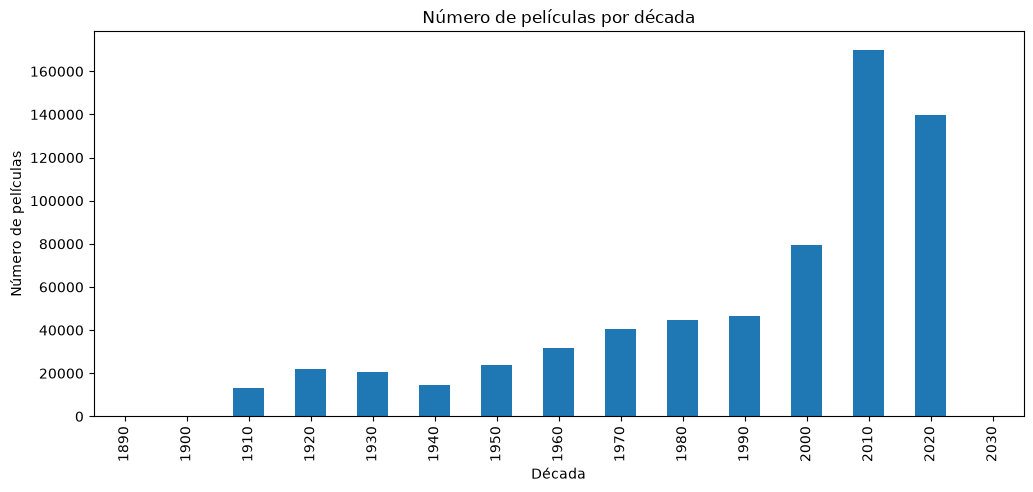

In [ ]:
# Comprobamos que tenemmos un número de películas decente para hacer el estudio en todas las décadas. Parece que si que lo tenemos
# Además le añadimos a my_movies una columna llamada decade
my_movies["decade"] = (my_movies["release_year"]//10*10).astype("Int64")

my_movies["decade"].value_counts().sort_index().plot(kind="bar",figsize=(12,5))

plt.title("Número de películas por década")
plt.xlabel("Década")
plt.ylabel("Número de películas")
plt.show()

In [ ]:
# Añadimos dos columnas en my_movies, que almacenan el número de caracteres (synopsis_length) y el número de letras (synopsis_words)
#   de cada sinopsis
my_movies["synopsis_length"] = my_movies["synopsis"].str.len()
my_movies["synopsis_words"] = (my_movies["synopsis"].str.split().str.len())

In [56]:
my_movies["synopsis_words"].describe()

count    20042.000000
mean       357.939926
std        330.020538
min          6.000000
25%        102.000000
50%        240.000000
75%        554.000000
max       3664.000000
Name: synopsis_words, dtype: float64

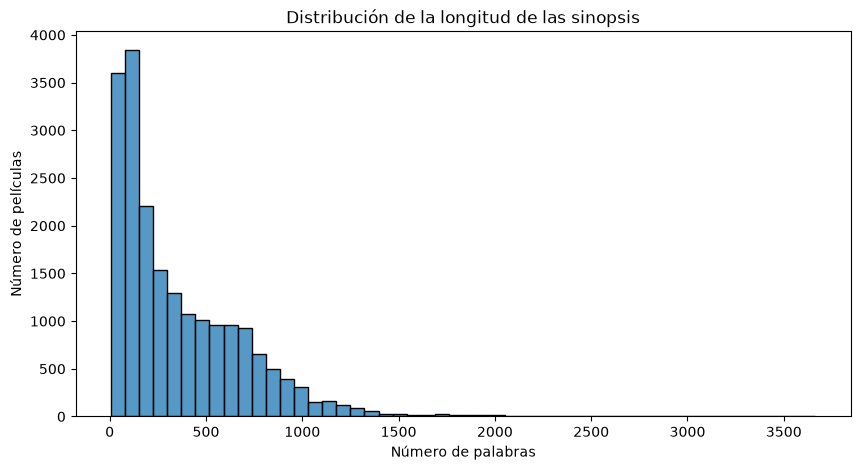

In [57]:
plt.figure(figsize=(10, 5))

sns.histplot(data=my_movies,x="synopsis_words",bins=50)

plt.title("Distribución de la longitud de las sinopsis")
plt.xlabel("Número de palabras")
plt.ylabel("Número de películas")

plt.show()

In [58]:
sinopsis_cortas = my_movies[my_movies["synopsis_words"] < 20][["title", "release_year", "synopsis", "synopsis_words"]]
display(sinopsis_cortas.head(20))

,title,release_year,synopsis,synopsis_words
543,In the Land of the Head Hunters,1914,The following plot synopsis was published in c...,19.0
1045,Four Feathers,1915,Considered a coward by his fiancée and comrade...,18.0
1889,Liberty,1916,"Liberty Horton, an American heiress, is kidnap...",17.0
8453,The Snob,1924,"Two schoolteachers, married for love, are part...",17.0
9130,The Only Thing,1925,"Adventures of an English duke-diplomat, mythic...",16.0
9874,Love's Blindness,1926,Hubert Culverdale is the hard-up and hard-to-...,17.0
13133,Leathernecking,1930,A Marine private successfully romances a socie...,16.0
13530,Young Man of Manhattan,1930,Jealousy comes between a couple when the wife ...,18.0
13619,Business and Pleasure,1932,Earl Tinker goes on a Mediterranean cruise an...,19.0
13820,A Holy Terror,1931,{{Expand section}} A man finds his father murd...,18.0


In [ ]:
# Comprobamos si hay sinopsis que, aunque no estén vacías, no aportan nada. En este caso a un total de 641 'unknown'
patrones = ["no plot summary","plot unknown","no synopsis available","unknown"]

for patron in patrones:
    coincidencias = my_movies[my_movies["synopsis"].str.contains(patron, case=False, na=False)]
    print(f"{patron}: {len(coincidencias)}")

no plot summary: 0
plot unknown: 0
no synopsis available: 0
unknown: 641


In [ ]:
my_movies[my_movies["synopsis"].duplicated(keep=False) & my_movies["synopsis"].notna()].sort_values("synopsis")

,movie_id,title,original_title,release_year,director,genres,title_key,production_country,synopsis,languages,paises_norm,decade,synopsis_length,synopsis_words
526166,tt33368396,Flash Gordon,Flash Gordon,1936,Frederick Stephani,"Action,Adventure,Sci-Fi",flash gordon,United States of America,# The Planet of Peril #: The planet Mongo is o...,English Language,United States,1930,2744.0,497.0
18158,tt0027623,Flash Gordon,Flash Gordon,1936,NaN,"Action,Adventure,Family",flash gordon,United States of America,# The Planet of Peril #: The planet Mongo is o...,English Language,United States,1930,2744.0,497.0
566276,tt3721574,I Am,I Am,<NA>,Vincent Sabella,Drama,i am,NaN,"*""Afia"" - A single woman decides to become a ...","Kannada Language, Bengali Language",,<NA>,884.0,100.0
711904,tt7380694,I Am,I Am,<NA>,Terence H. Winkless,Thriller,i am,NaN,"*""Afia"" - A single woman decides to become a ...","Kannada Language, Bengali Language",,<NA>,884.0,100.0
363930,tt1714851,I Am,I Am,<NA>,NaN,Drama,i am,NaN,"*""Afia"" - A single woman decides to become a ...","Kannada Language, Bengali Language",,<NA>,884.0,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
729601,tt8241560,Fiction,Fiction,<NA>,NaN,Crime,fiction,Spain,"Àlex, a shy and reserved filmmaker suffering f...",Spanish Language,Spain,<NA>,3117.0,525.0
585339,tt38799304,Fiction,Fiction,<NA>,Anocha Suwichakornpong,NaN,fiction,Spain,"Àlex, a shy and reserved filmmaker suffering f...",Spanish Language,Spain,<NA>,3117.0,525.0
571147,tt37593930,Fiction,Fiction,<NA>,Arin Lister,"Biography,Comedy,Drama",fiction,Spain,"Àlex, a shy and reserved filmmaker suffering f...",Spanish Language,Spain,<NA>,3117.0,525.0
428689,tt2365837,Fiction,Fiction,<NA>,B.C. Field,Drama,fiction,Spain,"Àlex, a shy and reserved filmmaker suffering f...",Spanish Language,Spain,<NA>,3117.0,525.0


In [ ]:
# Número de películas de cada idioma
idiomas = (my_movies["languages"].dropna().str.split(", ").explode().str.strip())
idiomas.value_counts().head(20)

languages
English Language      19120
French Language        1544
Hindi Language         1447
Silent film            1212
Spanish Language       1092
German Language         977
Japanese Language       863
Italian Language        836
Tamil Language          665
Korean Language         521
Standard Mandarin       491
Telugu language         483
Russian Language        398
Cantonese               337
Malayalam Language      331
Danish Language         287
Swedish Language        243
Dutch Language          218
Arabic Language         192
Urdu Language           175
Name: count, dtype: int64

In [64]:
for col in my_movies.select_dtypes(include=["object", "string"]).columns:
    for i, valor in my_movies[col].items():
        try:
            str(valor).encode("utf-8")
        except UnicodeEncodeError:
            print(f"Columna: {col} | Índice: {i} | Valor: {repr(valor)}")

Columna: languages | Índice: 314342 | Valor: 'Polish Language, Ukrainian Language, \ud801\udc16\ud801\udc32\ud801\udc49\ud801\udc4b\ud801\udc4c\ud801\udc32, Yiddish Language, German Language'
Columna: languages | Índice: 319887 | Valor: 'Croatian language, Italian Language, Russian Language, Spanish Language, French Language, \ud801\udc16\ud801\udc32\ud801\udc49\ud801\udc4b\ud801\udc4c\ud801\udc32, Portuguese Language, English Language, Slovenian language, German Language, Korean Language'
Columna: languages | Índice: 323181 | Valor: 'Italian Language, Spanish Language, French Language, \ud801\udc16\ud801\udc32\ud801\udc49\ud801\udc4b\ud801\udc4c\ud801\udc32, Latin Language, English Language, Polish Language, German Language'
Columna: languages | Índice: 338149 | Valor: 'English Language, \ud801\udc16\ud801\udc32\ud801\udc49\ud801\udc4b\ud801\udc4c\ud801\udc32, Russian Language, German Language'
Columna: languages | Índice: 359475 | Valor: '\ud801\udc16\ud801\udc32\ud801\udc49\ud801\ud

In [65]:
my_movies["languages"]=my_movies["languages"].str.encode("utf-8",errors="replace").str.decode("utf-8")

In [ ]:
# Exportamos y guardamos automáticamente my_movies.csv
my_movies.to_csv("my_movies.csv", index=False, encoding="utf-8-sig")

In [ ]:
my_movies["decade"] = (my_movies["release_year"] // 10) * 10

sinopsis_decada = (
    my_movies.groupby("decade")
    .agg(total_peliculas=("movie_id", "count"), con_sinopsis=("synopsis", "count"), sin_sinopsis=("synopsis", lambda x: x.isna().sum()))
)

sinopsis_decada["cobertura (%)"] = (sinopsis_decada["con_sinopsis"] /sinopsis_decada["total_peliculas"]*100).round(2)

sinopsis_decada

,total_peliculas,con_sinopsis,sin_sinopsis,cobertura (%)
decade,,,,
1890,18,2,16,11.11
1900,183,3,180,1.64
1910,12964,132,12832,1.02
1920,22085,348,21737,1.58
1930,20586,805,19781,3.91
1940,14730,871,13859,5.91
1950,23854,970,22884,4.07
1960,31900,872,31028,2.73
1970,40727,981,39746,2.41


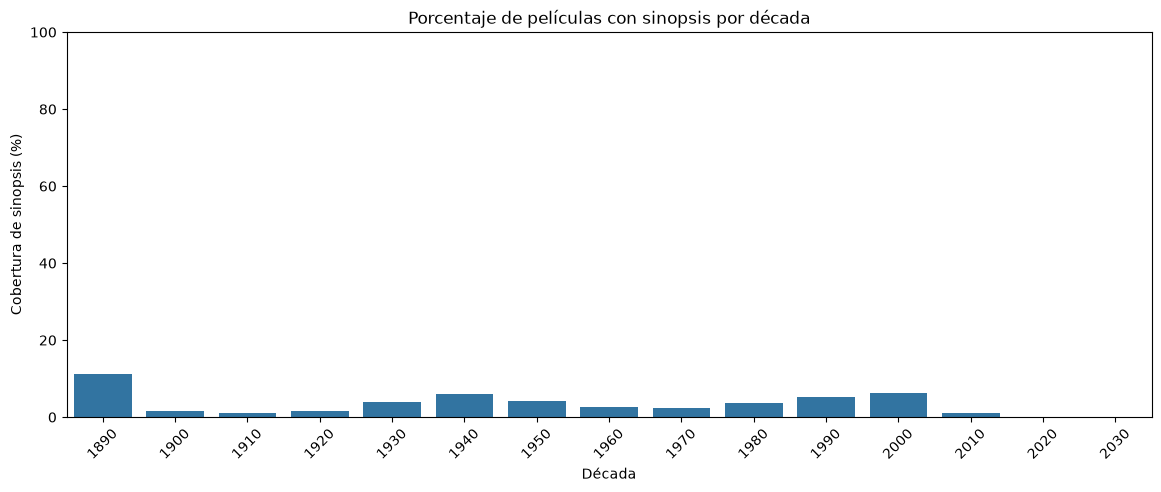

In [68]:
plt.figure(figsize=(14, 5))

sns.barplot(data=sinopsis_decada.reset_index(),x="decade",y="cobertura (%)")

plt.title("Porcentaje de películas con sinopsis por década")
plt.xlabel("Década")
plt.ylabel("Cobertura de sinopsis (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.show()